# 03 – Model Optimization (XGBRegressor + CAC Loss)

- Split por evento (sem leakage)  
- Cross-Validation com GroupKFold  
- Tuning com Optuna  
- Avaliação final com a métrica da ESA (L, MSE_HR, F2)  

**Antes de correr:**  
1. Garante que tens `metrics.py` no projeto.  
2. Ajusta o caminho para `train_data_features.csv`.  
3. `pip install optuna xgboost` se faltar.


In [16]:
# ============== 0) Imports & Config ==================
import numpy as np
import pandas as pd
from pathlib import Path
from importlib.machinery import SourceFileLoader

from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from xgboost import XGBRegressor
import optuna
import matplotlib.pyplot as plt

EVENT_COL, TARGET_COL = "event_id", "risk"
THR_LOG, BETA = -6.0, 2.0

# ============== 1) Carregar metrics.py ==================
metrics_file = None
for up in [Path.cwd(), *Path.cwd().parents]:
    for p in up.rglob("metrics.py"):
        metrics_file = p
        break
    if metrics_file:
        break
if metrics_file is None:
    raise FileNotFoundError("metrics.py não encontrado.")

metrics = SourceFileLoader("metrics", str(metrics_file)).load_module()
cac_loss      = metrics.cac_loss
build_report  = metrics.build_report
cac_scorer    = metrics.cac_scorer
find_best_thr = metrics.find_best_threshold

print("metrics.py:", metrics_file)


metrics.py: c:\Users\andal\OneDrive\Ambiente de Trabalho\cenas_satelites\utils\metrics.py


## 2) Carregar dados e split por evento


In [17]:
# AJUSTA O CAMINHO AQUI:
DATA_PATH = Path(r"..\\csv\\train_data_features.csv")

df_all = pd.read_csv(DATA_PATH)
assert {EVENT_COL, TARGET_COL}.issubset(df_all.columns)

events = df_all[EVENT_COL].unique()
train_ev, test_ev = train_test_split(events, test_size=0.2, random_state=42)

train_df = df_all[df_all[EVENT_COL].isin(train_ev)].copy()
test_df  = df_all[df_all[EVENT_COL].isin(test_ev)].copy()

X_train = train_df.drop(columns=[TARGET_COL])
y_train = train_df[TARGET_COL].values
X_test  = test_df.drop(columns=[TARGET_COL])
y_test  = test_df[TARGET_COL].values

print("Train events:", len(train_ev), "| Test events:", len(test_ev))
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)


Train events: 8613 | Test events: 2154
Train shape: (8613, 11)  Test shape: (2154, 11)


## 3) Funções utilitárias


In [18]:
def build_preprocessor(X: pd.DataFrame):
    num_cols = X.select_dtypes(include=np.number).columns.tolist()
    cat_cols = [c for c in X.columns if c not in num_cols]
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc",  StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)
    ])
    return pre

def fit_xgb(X_tr, y_tr, X_val=None, y_val=None, params=None, pre=None):
    if pre is None:
        pre = build_preprocessor(X_tr)
    pre.fit(X_tr, y_tr)
    X_tr_t = pre.transform(X_tr)
    model = XGBRegressor(**(params or {}))
    if X_val is not None:
        X_val_t = pre.transform(X_val)
        model.fit(X_tr_t, y_tr, eval_set=[(X_val_t, y_val)],
                  early_stopping_rounds=50, verbose=False)
    else:
        model.fit(X_tr_t, y_tr)
    return pre, model

def evaluate_model(pre, model, X_te, y_te, name="exp"):
    X_te_t = pre.transform(X_te)
    y_pred = model.predict(X_te_t)
    L, mse_hr, f2 = cac_loss(y_te, y_pred, thr_log=THR_LOG, beta=BETA)
    rep = build_report(name, y_te, y_pred, thr_log=THR_LOG, beta=BETA)
    return rep, y_pred, (L, mse_hr, f2)


## 4) Cross‑Validation (GroupKFold)


In [19]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

pre_tune = build_preprocessor(X_tr)
pre_tune.fit(X_tr, y_tr)
Xt_tr = pre_tune.transform(X_tr)
Xt_val = pre_tune.transform(X_val)

from xgboost.callback import EarlyStopping

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 400, 2000),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_float("min_child_weight", 1e-2, 10.0, log=True),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
        "random_state": 42,
        "tree_method": "hist",
        "n_jobs": -1
    }
    mdl = XGBRegressor(**params)
    mdl.fit(Xt_tr, y_tr)  # <-- sem ES
    y_pred = mdl.predict(Xt_val)
    L, _, _ = cac_loss(y_val, y_pred, thr_log=THR_LOG, beta=BETA)
    return L



study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=40, show_progress_bar=False)

best_params = study.best_params
best_params.update({"random_state":42, "tree_method":"hist", "n_jobs":-1})
print(best_params)




[I 2025-07-24 01:44:06,496] A new study created in memory with name: no-name-2fd6414d-aef0-4174-93df-aac85117815a
[I 2025-07-24 01:44:07,245] Trial 0 finished with value: 12.851586599209739 and parameters: {'n_estimators': 1410, 'learning_rate': 0.0834757933130218, 'max_depth': 9, 'subsample': 0.6547130514407749, 'colsample_bytree': 0.8289585455443946, 'min_child_weight': 0.9421033577993035, 'gamma': 2.3688479022808133}. Best is trial 0 with value: 12.851586599209739.
[I 2025-07-24 01:44:07,913] Trial 1 finished with value: 15.106855863523146 and parameters: {'n_estimators': 836, 'learning_rate': 0.048667688150760925, 'max_depth': 5, 'subsample': 0.7186334834776107, 'colsample_bytree': 0.522388356541198, 'min_child_weight': 7.62918601394244, 'gamma': 4.5338156216344165}. Best is trial 0 with value: 12.851586599209739.
[I 2025-07-24 01:44:08,536] Trial 2 finished with value: 16.40275083533888 and parameters: {'n_estimators': 854, 'learning_rate': 0.024695427054437405, 'max_depth': 4, 's

{'n_estimators': 673, 'learning_rate': 0.013639708674421517, 'max_depth': 10, 'subsample': 0.9949460606444351, 'colsample_bytree': 0.9894651176811063, 'min_child_weight': 6.572050513578807, 'gamma': 4.960369938570963, 'random_state': 42, 'tree_method': 'hist', 'n_jobs': -1}


## 5) Tuning com Optuna


In [20]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

pre_tune = build_preprocessor(X_tr)
pre_tune.fit(X_tr, y_tr)
Xt_tr = pre_tune.transform(X_tr)
Xt_val = pre_tune.transform(X_val)

from xgboost.callback import EarlyStopping

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 400, 2000),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_float("min_child_weight", 1e-2, 10.0, log=True),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
        "random_state": 42,
        "tree_method": "hist",
        "n_jobs": -1
    }
    mdl = XGBRegressor(**params)
    mdl.fit(Xt_tr, y_tr)                      # <-- sem early_stopping_rounds
    y_pred = mdl.predict(Xt_val)
    L, _, _ = cac_loss(y_val, y_pred, thr_log=THR_LOG, beta=BETA)
    return L



study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=40, show_progress_bar=False)

best_params = study.best_params
best_params.update({"random_state":42, "tree_method":"hist", "n_jobs":-1})
best_params


[I 2025-07-24 01:44:52,308] A new study created in memory with name: no-name-d7729130-6b97-4b04-89b4-ae02069b1df2
[I 2025-07-24 01:44:52,909] Trial 0 finished with value: 12.975847112470854 and parameters: {'n_estimators': 642, 'learning_rate': 0.03671781881426647, 'max_depth': 10, 'subsample': 0.9795749810353733, 'colsample_bytree': 0.7102470109631516, 'min_child_weight': 5.599942490076852, 'gamma': 3.4543553749839067}. Best is trial 0 with value: 12.975847112470854.
[I 2025-07-24 01:44:53,524] Trial 1 finished with value: 11.913032230627222 and parameters: {'n_estimators': 1563, 'learning_rate': 0.0851698314786911, 'max_depth': 11, 'subsample': 0.8274436727544704, 'colsample_bytree': 0.934728182796312, 'min_child_weight': 0.01241428944956468, 'gamma': 4.370738913423589}. Best is trial 1 with value: 11.913032230627222.
[I 2025-07-24 01:44:55,497] Trial 2 finished with value: 10.546214211952945 and parameters: {'n_estimators': 835, 'learning_rate': 0.011317915144638035, 'max_depth': 12

{'n_estimators': 1310,
 'learning_rate': 0.0215394985097194,
 'max_depth': 6,
 'subsample': 0.7127870349852665,
 'colsample_bytree': 0.7831616916237485,
 'min_child_weight': 0.6677322768256416,
 'gamma': 0.6686199231771519,
 'random_state': 42,
 'tree_method': 'hist',
 'n_jobs': -1}

## 6) Treino final + teste


In [21]:
pre_best, mdl_best = fit_xgb(X_train, y_train, params=best_params)
rep_test, y_pred_test, (L_test, mse_hr_test, f2_test) = evaluate_model(pre_best, mdl_best, X_test, y_test, name="xgb_optuna")

print(f"TEST -> L={L_test:.4f} | MSE_HR={mse_hr_test:.4f} | F2={f2_test:.4f}")
display(rep_test)

best_thr, best_f2 = find_best_thr(y_test, y_pred_test, beta=BETA)
print(f"Melhor threshold (test) = {best_thr:.3f}  |  F2={best_f2:.4f}")

rep_test.to_csv("artifacts/xgb_test_optuna_report.csv", index=False)


TEST -> L=5.0357 | MSE_HR=2.6806 | F2=0.5323


,name,L,MSE_HR,F2,thr_log,beta
0,xgb_optuna,5.035665,2.680582,0.532319,-6.0,2.0


Melhor threshold (test) = -4.350  |  F2=0.5556


## 7) Plot L por fold


,fold,L,MSE_HR,F2
0,0,12.591730,6.046876,0.480226
1,1,11.633073,5.360863,0.460829
2,2,8.876359,4.824108,0.543478
3,3,23.645590,12.154275,0.514019
4,4,9.345401,6.614325,0.707763


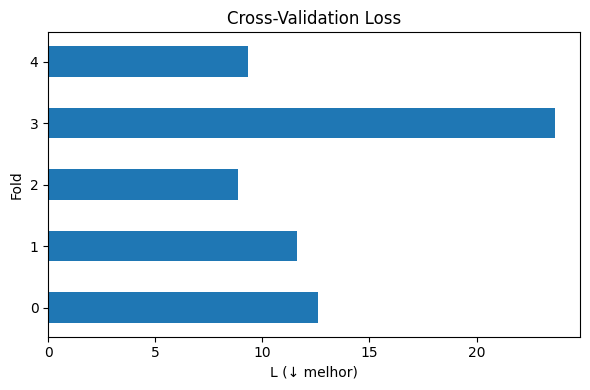

In [24]:
from sklearn.model_selection import GroupKFold
cv_rows = []
gkf = GroupKFold(n_splits=5)

base_params = dict(
    n_estimators=800,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    tree_method="hist",
    n_jobs=-1
)

for fold, (tr_idx, va_idx) in enumerate(gkf.split(train_df, groups=train_df[EVENT_COL])):
    tr_df = train_df.iloc[tr_idx]
    va_df = train_df.iloc[va_idx]

    X_tr, y_tr = tr_df.drop(columns=[TARGET_COL]), tr_df[TARGET_COL].values
    X_va, y_va = va_df.drop(columns=[TARGET_COL]), va_df[TARGET_COL].values

    # fit + eval (usa as tuas funções se já as tens)
    pre = build_preprocessor(X_tr)
    pre.fit(X_tr, y_tr)
    X_tr_t = pre.transform(X_tr)
    X_va_t = pre.transform(X_va)

    mdl = XGBRegressor(**base_params)
    mdl.fit(X_tr_t, y_tr)

    y_pred_va = mdl.predict(X_va_t)
    L, mse_hr, f2 = cac_loss(y_va, y_pred_va, thr_log=THR_LOG, beta=BETA)

    cv_rows.append({"fold": fold, "L": L, "MSE_HR": mse_hr, "F2": f2})

cv_df = pd.DataFrame(cv_rows)
display(cv_df)


fig, ax = plt.subplots(figsize=(6,4))
ax.barh(cv_df["fold"], cv_df["L"], height=0.5)
ax.set_xlabel("L (↓ melhor)")
ax.set_ylabel("Fold")
ax.set_title("Cross-Validation Loss")
plt.tight_layout()
plt.show()

